# BMW Sales Data | Exploratory Analysis

> **Portfolio project ? Data analysis ? Python**

A reproducible exploration of 50,000 BMW sales records spanning 2010?2024. The analysis examines reported sales volume over time and by model, listed prices by fuel type, and relationships among numeric fields.

## Executive summary

The dataset is broadly balanced across years, models, and fuel types. Average reported sales volume and listed price vary only modestly across groups, so these records do not support a strong ranking or a confident market-trend claim. The source does not define the record grain, sales-volume units, or how its `High` / `Low` classification is assigned; those limitations shape the conclusions below.

**Tools:** Python ? pandas ? Matplotlib ? Seaborn  
**Data:** `BMW sales data (2010-2024).csv` (provided alongside this notebook)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#30343b",
    "text.color": "#20242a",
})

## 1. Load and validate the source

Keep the CSV next to this notebook and run the cells from this folder. The checks below report completeness, duplicate rows, and basic value ranges before any charts are produced. No records are silently removed or imputed.

In [2]:
data_path = Path("BMW sales data (2010-2024).csv")
if not data_path.is_file():
    raise FileNotFoundError(
        f"Could not find {data_path.name!r} in {Path.cwd()}. "
        "Place the source CSV beside this notebook and rerun."
    )

df = pd.read_csv(data_path)
required_columns = {
    "Model", "Year", "Region", "Color", "Fuel_Type", "Transmission",
    "Engine_Size_L", "Mileage_KM", "Price_USD", "Sales_Volume",
    "Sales_Classification",
}
missing_columns = sorted(required_columns.difference(df.columns))
if missing_columns:
    raise ValueError(f"Source CSV is missing required columns: {missing_columns}")

quality_summary = pd.DataFrame({"Result": [
    f"{len(df):,} rows ? {df.shape[1]} columns",
    f"{df['Year'].min()}?{df['Year'].max()}",
    f"{df.isna().sum().sum():,}",
    f"{df.duplicated().sum():,}",
    f"{(df[['Price_USD', 'Sales_Volume']] <= 0).sum().sum():,}",
]}, index=[
    "Dataset size", "Year range", "Missing cells", "Duplicate rows",
    "Non-positive prices / volumes",
])

print(f"Source file: {data_path.resolve()}")
display(quality_summary)
display(df.head())

Source file: C:\Python Programming\BMW sales data (2010-2024).csv


,Result
Dataset size,"50,000 rows ? 11 columns"
Year range,2010?2024
Missing cells,0
Duplicate rows,0
Non-positive prices / volumes,0


,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
0,5 Series,2016,Asia,Red,Petrol,Manual,3.5,151748,98740,8300,High
1,i8,2013,North America,Red,Hybrid,Automatic,1.6,121671,79219,3428,Low
2,5 Series,2022,North America,Blue,Petrol,Automatic,4.5,10991,113265,6994,Low
3,X3,2024,Middle East,Blue,Petrol,Automatic,1.7,27255,60971,4047,Low
4,7 Series,2020,South America,Black,Diesel,Manual,2.1,122131,49898,3080,Low


### Scope and interpretation

- **One row is one source record.** Its business meaning and whether `Sales_Volume` is a unit count, a period total, or another measure are undocumented.
- `Price_USD` is treated as a listed price in USD; the source does not explain whether it is new, used, or transaction pricing.
- Group comparisons use **mean `Sales_Volume` per record**, not sums. Summing can make a group look larger simply because it has more rows.
- No revenue is estimated: multiplying price by an undefined volume measure could produce a misleading figure. The `Sales_Classification` field is excluded because its rule is not documented.
- These are descriptive associations in the supplied dataset, not causal findings or verified statements about BMW's actual market performance.

## 2. Reported sales volume over time

The line shows the **average reported sales volume per row** in each year. This normalizes for the slight differences in annual record counts; the dashed reference is the dataset-wide average.

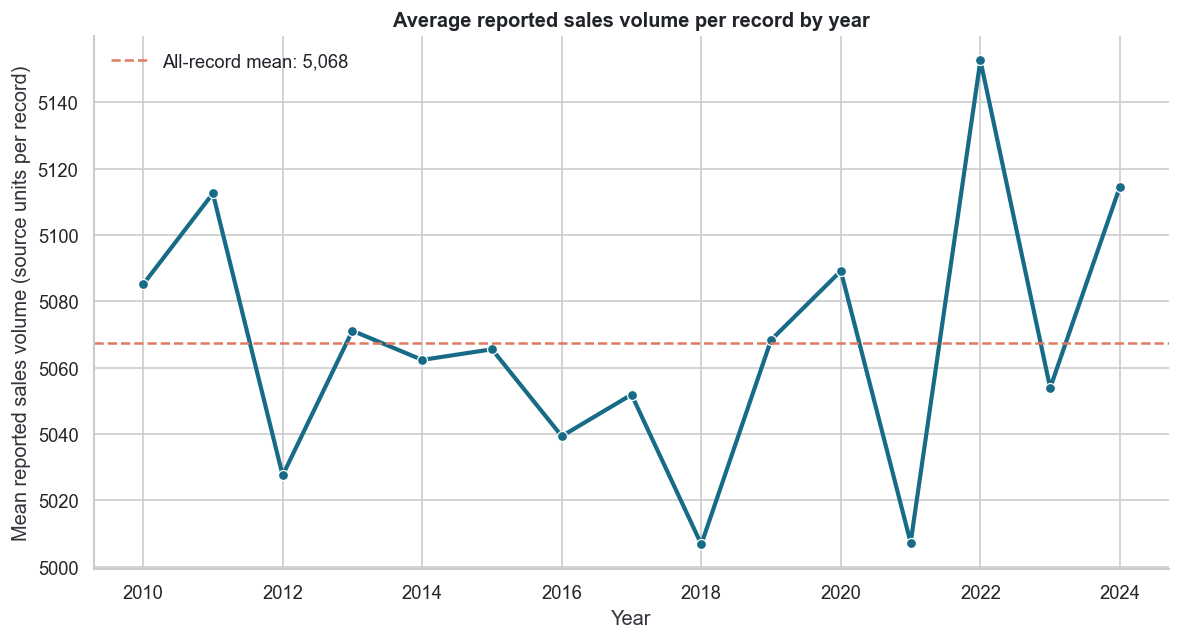

Annual mean ranges from 5,007 (2018) to 5,153 (2022); interpret these as source-reported values, not verified market totals.


In [3]:
annual = (
    df.groupby("Year", as_index=False)
      .agg(mean_sales_volume=("Sales_Volume", "mean"), record_count=("Sales_Volume", "size"))
)
overall_mean = df["Sales_Volume"].mean()
peak_year = int(annual.loc[annual["mean_sales_volume"].idxmax(), "Year"])
low_year = int(annual.loc[annual["mean_sales_volume"].idxmin(), "Year"])

fig, ax = plt.subplots()
sns.lineplot(data=annual, x="Year", y="mean_sales_volume", marker="o", linewidth=2.5, color="#176B87", ax=ax)
ax.axhline(overall_mean, color="#E07A5F", linestyle="--", linewidth=1.5,
           label=f"All-record mean: {overall_mean:,.0f}")
ax.set(title="Average reported sales volume per record by year",
       xlabel="Year", ylabel="Mean reported sales volume (source units per record)")
ax.set_xticks(annual["Year"].iloc[::2])
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
plt.show()

print(f"Annual mean ranges from {annual['mean_sales_volume'].min():,.0f} ({low_year}) "
      f"to {annual['mean_sales_volume'].max():,.0f} ({peak_year}); interpret these as "
      "source-reported values, not verified market totals.")

## 3. Model comparison

Models are ordered by mean reported sales volume per record. The bar lengths start at zero to avoid exaggerating relatively small differences. The dataset is nearly balanced in the number of records per model, but per-model row counts remain part of the summary.

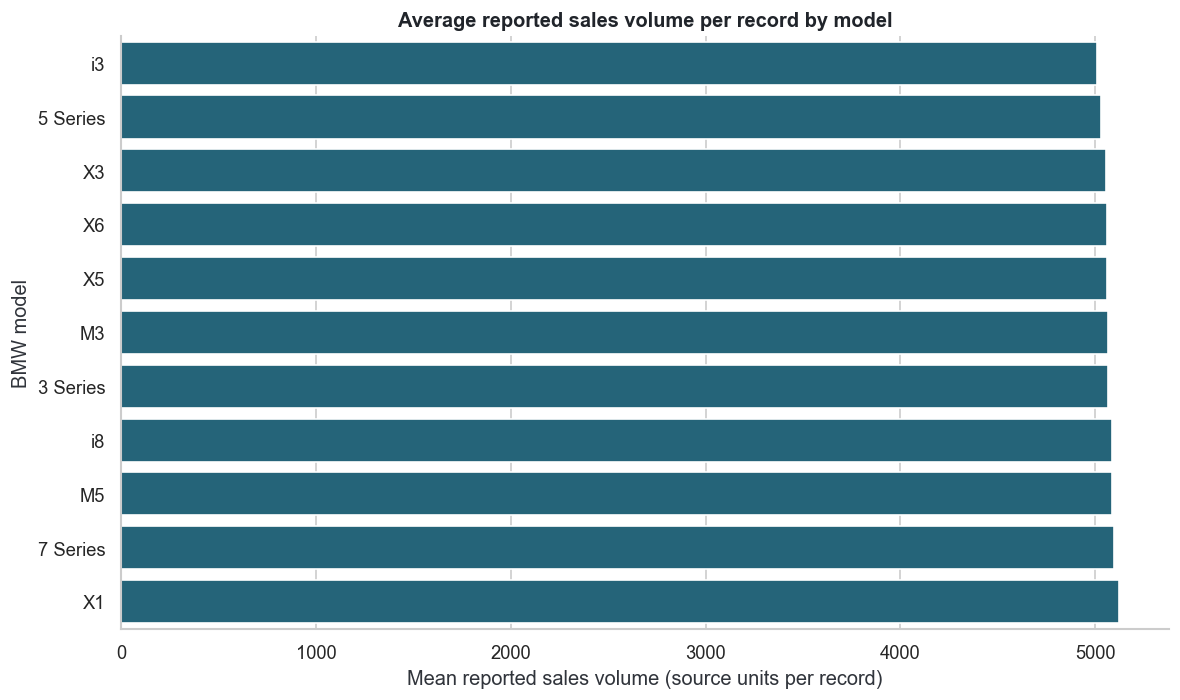

,Model,Mean volume per record,Record count
5,X1,5121.7,4570
2,7 Series,5097.8,4666
4,M5,5087.0,4478


In [4]:
model_summary = (
    df.groupby("Model", as_index=False)
      .agg(mean_sales_volume=("Sales_Volume", "mean"), record_count=("Sales_Volume", "size"))
      .sort_values("mean_sales_volume", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=model_summary, x="mean_sales_volume", y="Model", color="#176B87", ax=ax)
ax.set(title="Average reported sales volume per record by model",
       xlabel="Mean reported sales volume (source units per record)", ylabel="BMW model")
ax.set_xlim(left=0)
sns.despine()
fig.tight_layout()
plt.show()

display(model_summary.nlargest(3, "mean_sales_volume")
        .rename(columns={"mean_sales_volume": "Mean volume per record", "record_count": "Record count"})
        .round({"Mean volume per record": 1}))

## 4. Listed price by fuel type

The box plots compare the distribution of `Price_USD` across fuel types. Outlier markers are hidden only to keep the 50,000-row plot legible; the underlying data is unchanged. Similar distributions should not be read as evidence of equal ownership costs or vehicle value.

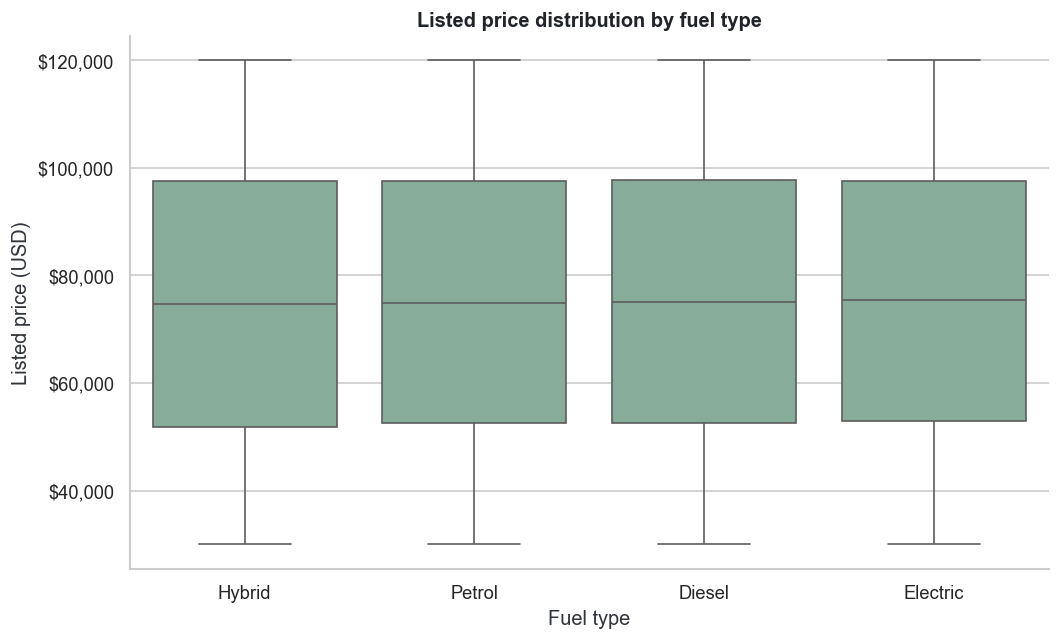

,Records,Median_USD,Mean_USD
Fuel_Type,,,
Hybrid,12716,74728.0,74798.0
Petrol,12550,74796.0,74990.0
Diesel,12263,75013.0,75080.0
Electric,12471,75425.0,75276.0


In [5]:
fuel_order = df.groupby("Fuel_Type")["Price_USD"].median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=df, x="Fuel_Type", y="Price_USD", order=fuel_order,
            color="#81B29A", showfliers=False, ax=ax)
ax.set(title="Listed price distribution by fuel type", xlabel="Fuel type", ylabel="Listed price (USD)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
sns.despine()
fig.tight_layout()
plt.show()

display(df.groupby("Fuel_Type")["Price_USD"]
        .agg(Records="size", Median_USD="median", Mean_USD="mean")
        .sort_values("Median_USD").round(0))

## 5. Numeric relationships

Pearson correlations summarize **linear association**, not causation. The full ?1 to +1 color scale is retained so weak relationships are not visually inflated. Values close to zero indicate little linear association in this sample; they do not prove that no relationship exists.

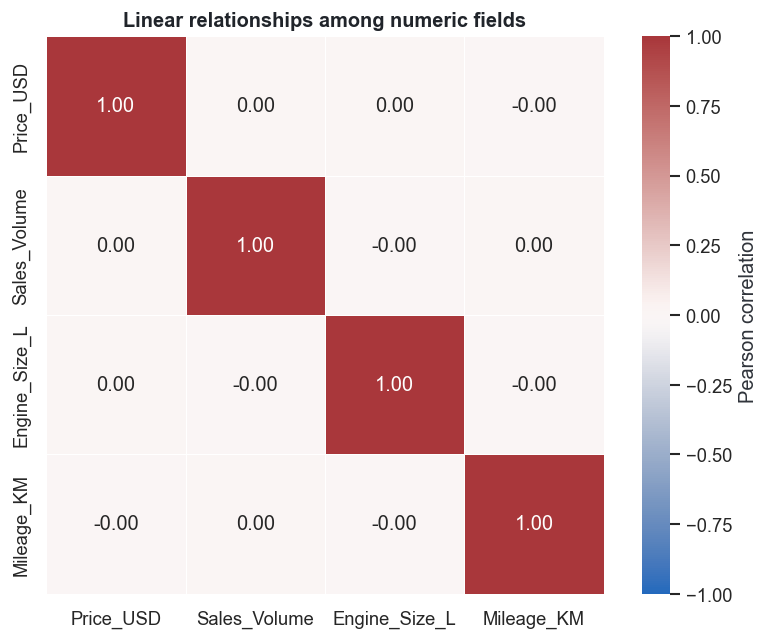

Largest absolute off-diagonal correlation: 0.005


In [6]:
numeric_features = ["Price_USD", "Sales_Volume", "Engine_Size_L", "Mileage_KM"]
correlations = df[numeric_features].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Linear relationships among numeric fields")
fig.tight_layout()
plt.show()

largest_abs_corr = correlations.unstack().drop(
    [(name, name) for name in correlations.columns]
).abs().max()
print(f"Largest absolute off-diagonal correlation: {largest_abs_corr:.3f}")

## Conclusion and next steps

This dataset supports a clear, reproducible **descriptive** workflow, but not a defensible estimate of real-world BMW revenue, market share, or demand. Its group averages are broadly similar, and the source documentation is not sufficient to interpret the volume measure or sales labels more strongly.

For a decision-grade follow-up, obtain a data dictionary and provenance, confirm the record grain and volume units, define the `High` / `Low` rule, and validate the records against an authoritative source. With those definitions, the next analysis could compare properly normalized trends and test segment differences with uncertainty intervals.

---

*All findings in this notebook are limited to the supplied CSV and its documented fields.*